# Banner exploration

`b2_download_file_by_id` is one zstd stream of **Shodan banners**: newline-delimited JSON, one observed service per line (IP, port, org, HTTP, CPE, CVEs, and a module-specific blob).

The compressed file is about 17 GB. This notebook reads `archive/data/samples/stride_200.ndjson`: every 200th line of that stream, written by `archive/scripts/eda/stride_sample.py`. Shares below are the share of this sample. Rows are not in timestamp order.

Use the **Python (fm-explore)** kernel, which is this repo's `.venv`.


In [1]:
import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "archive" else Path.cwd()
DATA = ROOT / "archive" / "data" / "samples" / "stride_200.ndjson"
if not DATA.exists():
    raise FileNotFoundError(DATA)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.figsize": (8, 4),
    "font.family": "Arial Unicode MS",
})

print(f"{DATA}  {DATA.stat().st_size / 1e6:.1f} MB")


Matplotlib is building the font cache; this may take a moment.


/Users/sukantaroy/interviews/caseStudies/fm-explore/data/stride_200.ndjson  616.7 MB


## Load the stride sample

DuckDB's CSV reader is only splitting lines. A delimiter that does not occur in the banners makes each line a single column. `strict_mode` is off because the payload is JSON, not CSV. HTML bodies and the raw `data` string stay out of the frame; `data_chars` is their length.


In [2]:
def load_sample() -> pd.DataFrame:
    path = str(DATA).replace("'", "''")
    con = duckdb.connect()
    df = con.execute(f"""
        SELECT
          json_extract_string(j, '$.ip_str') AS ip_str,
          json_extract_string(j, '$.ipv6') AS ipv6,
          json_extract(j, '$.port')::INTEGER AS port,
          json_extract_string(j, '$.transport') AS transport,
          json_extract_string(j, '$.timestamp') AS timestamp,
          json_extract_string(j, '$.org') AS org,
          json_extract_string(j, '$.isp') AS isp,
          json_extract_string(j, '$.asn') AS asn,
          json_extract_string(j, '$.os') AS os,
          json_extract_string(j, '$.product') AS product,
          json_extract_string(j, '$.version') AS version,
          json_extract_string(j, '$.location.country_code') AS country,
          json_extract_string(j, '$.location.country_name') AS country_name,
          json_extract_string(j, '$.location.city') AS city,
          json_extract_string(j, '$._shodan.module') AS module,
          TRY_CAST(json_extract_string(j, '$.http.status') AS INTEGER) AS http_status,
          json_extract_string(j, '$.http.title') AS http_title,
          json_extract_string(j, '$.http.server') AS http_server,
          json_extract_string(j, '$.hostnames[0]') AS hostname,
          json_array_length(json_extract(j, '$.hostnames')) AS n_hostnames,
          json_extract(j, '$.hostnames')::VARCHAR AS hostnames,
          json_extract_string(j, '$.domains[0]') AS domain,
          json_array_length(json_extract(j, '$.domains')) AS n_domains,
          json_extract(j, '$.domains')::VARCHAR AS domains,
          json_extract(j, '$.tags')::VARCHAR AS tags,
          json_extract_string(j, '$.cpe[0]') AS cpe,
          json_array_length(json_extract(j, '$.cpe')) AS n_cpe,
          json_extract(j, '$.cpe')::VARCHAR AS cpes,
          json_extract(j, '$.vulns') IS NOT NULL AS has_vulns,
          CASE
            WHEN json_extract(j, '$.vulns') IS NULL THEN 0
            ELSE json_array_length(json_keys(json_extract(j, '$.vulns')))
          END AS n_vulns,
          CASE
            WHEN json_extract(j, '$.vulns') IS NULL THEN NULL
            ELSE to_json(json_keys(json_extract(j, '$.vulns')))::VARCHAR
          END AS vuln_ids,
          json_extract(j, '$.ssl') IS NOT NULL AS has_ssl,
          json_extract_string(j, '$.cloud.provider') AS cloud_provider,
          json_extract_string(j, '$.cloud.service') AS cloud_service,
          length(json_extract_string(j, '$.data')) AS data_chars
        FROM (
          SELECT column0::JSON AS j
          FROM read_csv(
            '{path}',
            header = false,
            columns = {{'column0': 'VARCHAR'}},
            delim = '\x01',
            quote = '',
            escape = '',
            max_line_size = 50000000,
            strict_mode = false,
            ignore_errors = true
          )
        )
    """).fetchdf()
    con.close()
    df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True, format="ISO8601")
    return df


sample = load_sample()
print(
    f"{len(sample):,} banners   "
    f"{sample['timestamp'].min()}  →  {sample['timestamp'].max()}"
)
sample.head(3)


73,043 banners   2026-10-26 04:08:00.821811+00:00  →  2026-10-26 13:03:52.407260+00:00


,ip_str,ipv6,port,transport,timestamp,org,isp,asn,os,product,...,cpe,n_cpe,cpes,has_vulns,n_vulns,vuln_ids,has_ssl,cloud_provider,cloud_service,data_chars
0,141.193.213.20,NaN,443,tcp,2026-10-26 11:59:52.579107+00:00,"WPEngine, Inc.","Cloudflare London, LLC",AS209242,NaN,NaN,...,cpe:/a:cloudflare:cloudflare,1,"[""cpe:/a:cloudflare:cloudflare""]",False,0,NaN,True,NaN,NaN,2202
1,45.60.143.8,NaN,8531,tcp,2026-10-26 11:59:57.754820+00:00,Incapsula Inc,Incapsula Inc,AS19551,NaN,NaN,...,NaN,<NA>,NaN,False,0,NaN,False,NaN,NaN,0
2,192.230.66.72,NaN,785,tcp,2026-10-26 11:59:59.323031+00:00,Incapsula Inc,Incapsula Inc,AS19551,NaN,NaN,...,NaN,<NA>,NaN,False,0,NaN,False,NaN,NaN,0


## Which fields are actually filled in?

Most banners share a core (`port`, `org`, `asn`, `module`, `timestamp`). Product, OS, HTTP, CPE, and CVEs are present only on some of them. `ip_str` is empty on IPv6-only rows; those have `ipv6` instead. Empty lists count as absent. `has_ssl`, `has_vulns`, `n_vulns`, and `data_chars` are computed for every row, so they are left out here.


In [3]:
skip = ["has_ssl", "has_vulns", "n_vulns", "data_chars"]
view = sample.drop(columns=skip)

def occupied(col: pd.Series) -> pd.Series:
    text = col.astype("string").str.strip()
    return col.notna() & ~text.isin(["", "[]", "null", "None"])

mask = view.apply(occupied)
filled = pd.DataFrame({"occupied": mask.sum(), "share": mask.mean()}).sort_values("share")
filled.assign(share=lambda d: (d["share"] * 100).round(1).astype(str) + "%")


,occupied,share
ipv6,1622,2.2%
vuln_ids,2394,3.3%
os,3076,4.2%
cloud_service,4121,5.6%
version,4839,6.6%
http_title,12457,17.1%
product,13182,18.0%
http_server,14244,19.5%
cpes,15479,21.2%
cpe,15479,21.2%


In [4]:
def top_counts(series: pd.Series, n: int = 15, title: str = "") -> pd.Series:
    counts = (
        series.dropna()
        .astype(str)
        .str.strip()
        .replace({"": pd.NA, "None": pd.NA, "[]": pd.NA})
        .dropna()
        .value_counts()
        .head(n)
    )
    if counts.empty:
        print(f"{title}: no values")
        return counts
    fig, ax = plt.subplots(figsize=(8, max(2.4, 0.32 * len(counts))))
    counts.iloc[::-1].plot.barh(ax=ax, color="#3d5a80")
    ax.set_title(title or series.name or "")
    ax.set_xlabel(f"banners in this sample (n={len(sample):,})")
    fig.tight_layout()
    plt.show()
    return counts


## Where the IP is, and who announces it


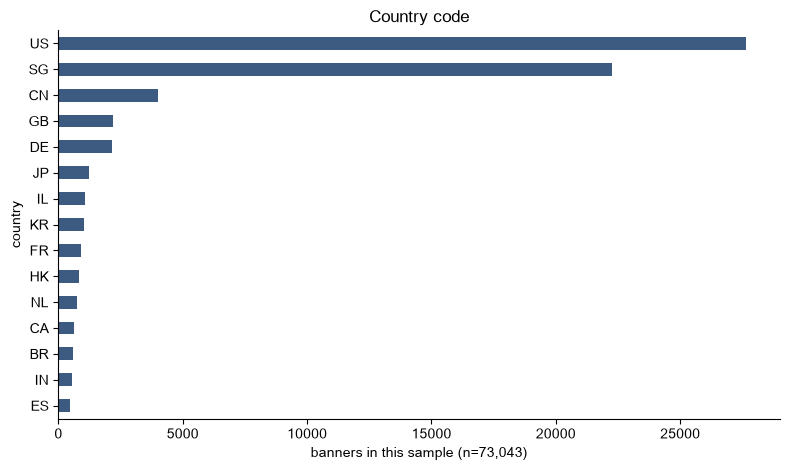

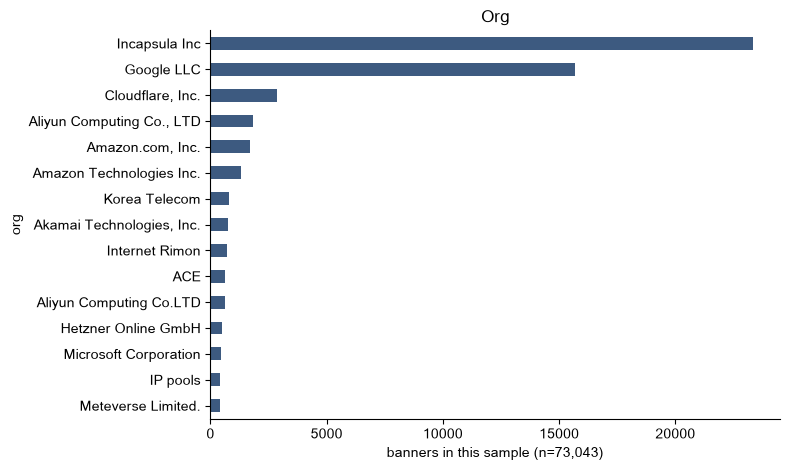

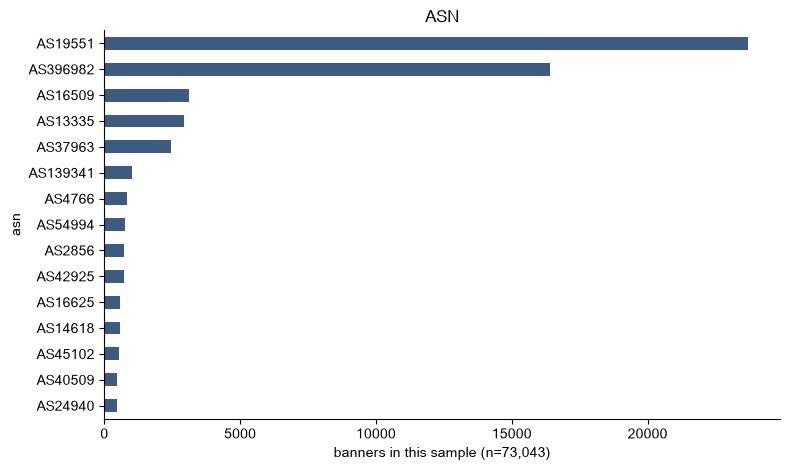

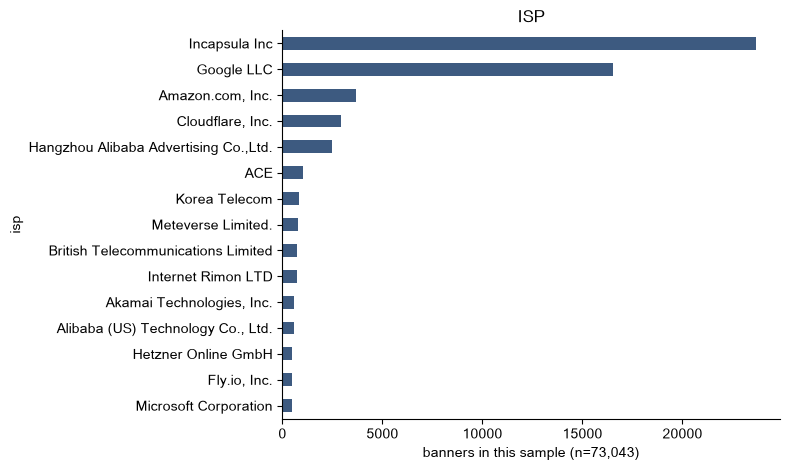

isp
Incapsula Inc                            23691
Google LLC                               16548
Amazon.com, Inc.                          3683
Cloudflare, Inc.                          2939
Hangzhou Alibaba Advertising Co.,Ltd.     2469
ACE                                       1012
Korea Telecom                              851
Meteverse Limited.                         757
British Telecommunications Limited         715
Internet Rimon LTD                         711
Akamai Technologies, Inc.                  594
Alibaba (US) Technology Co., Ltd.          558
Hetzner Online GmbH                        492
Fly.io, Inc.                               479
Microsoft Corporation                      476
Name: count, dtype: int64

In [5]:
top_counts(sample["country"], title="Country code")
top_counts(sample["org"], title="Org")
top_counts(sample["asn"], title="ASN")
top_counts(sample["isp"], title="ISP")


## What is listening

`module` is the Shodan probe that produced the banner (`https`, `ssh`, `snmp_v3`, …). `product` is only set when the probe named a piece of software.


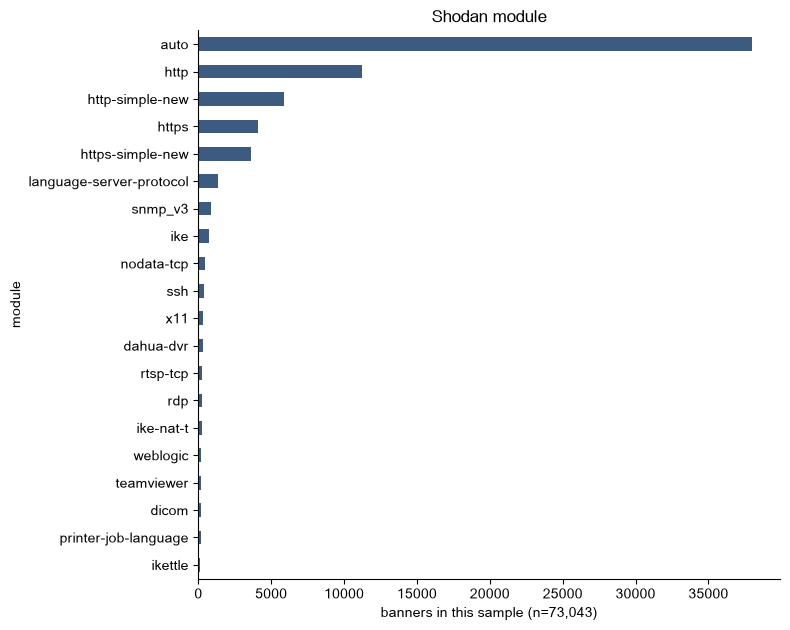

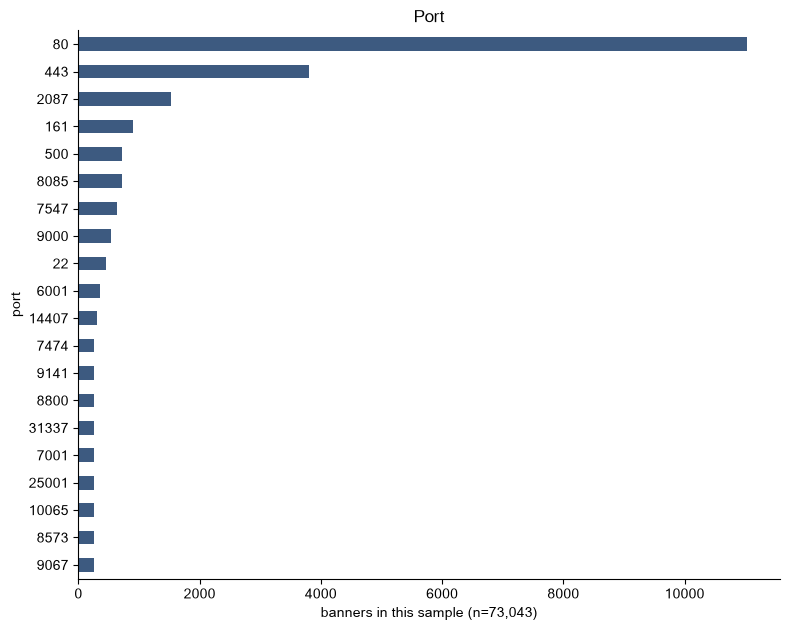

transport
tcp    70665
udp     2378
Name: count, dtype: int64


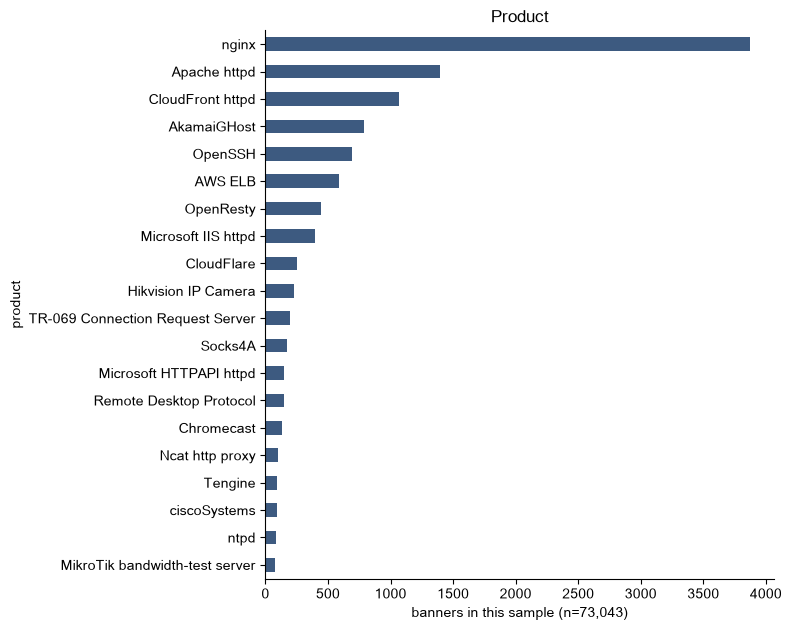

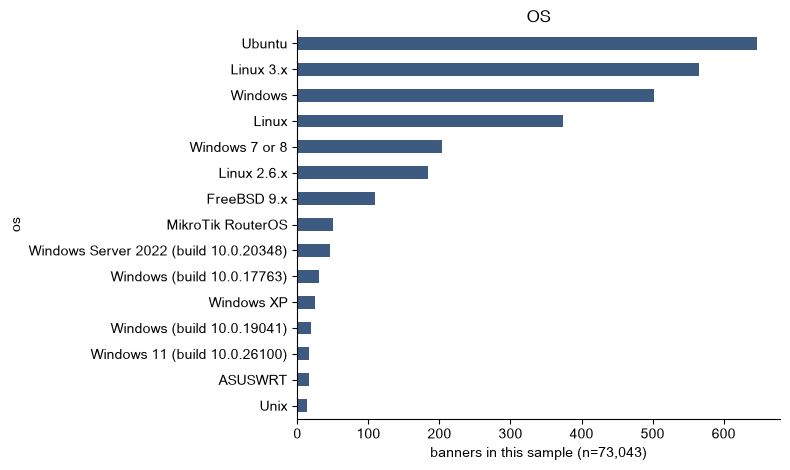

os
Ubuntu                                    647
Linux 3.x                                 565
Windows                                   502
Linux                                     374
Windows 7 or 8                            203
Linux 2.6.x                               184
FreeBSD 9.x                               110
MikroTik RouterOS                          50
Windows Server 2022 (build 10.0.20348)     46
Windows (build 10.0.17763)                 31
Windows XP                                 25
Windows (build 10.0.19041)                 19
Windows 11 (build 10.0.26100)              17
ASUSWRT                                    17
Unix                                       14
Name: count, dtype: int64

In [6]:
top_counts(sample["module"], n=20, title="Shodan module")
top_counts(sample["port"].astype("Int64").astype(str), n=20, title="Port")
print(sample["transport"].value_counts(dropna=False))
top_counts(sample["product"], n=20, title="Product")
top_counts(sample["os"], title="OS")


## HTTP surface

Status, title, and `Server` are filled only when the module spoke HTTP. Titles are a fast way to see login pages, device consoles, and default installs.


21,792 / 73,043 banners have an HTTP status


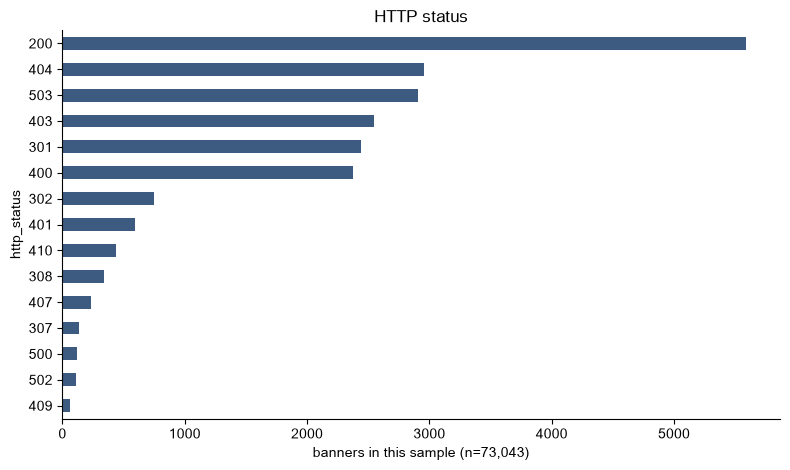

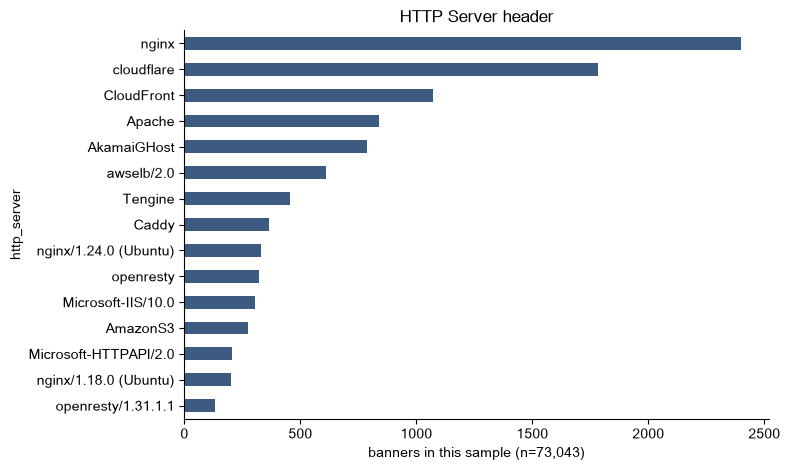

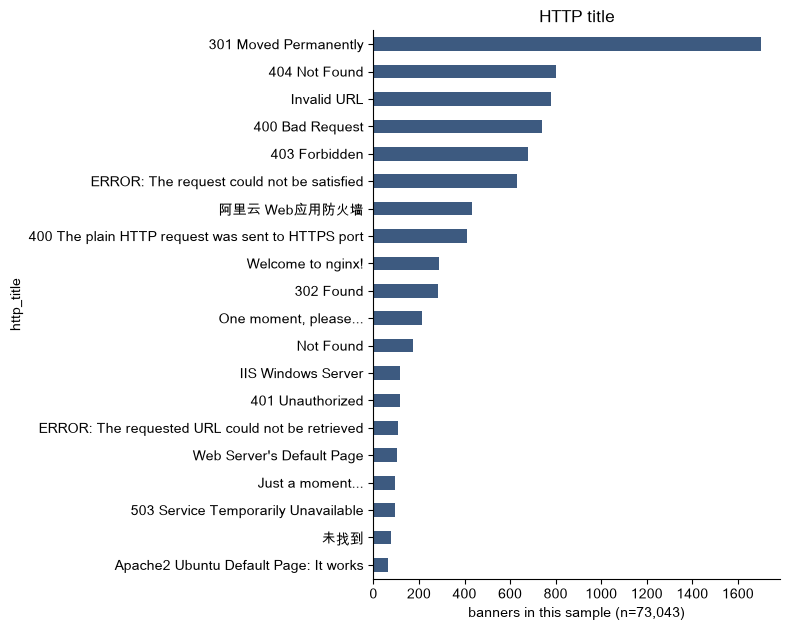

http_title
301 Moved Permanently                                1700
404 Not Found                                         803
Invalid URL                                           780
400 Bad Request                                       740
403 Forbidden                                         678
ERROR: The request could not be satisfied             631
阿里云 Web应用防火墙                                          433
400 The plain HTTP request was sent to HTTPS port     410
Welcome to nginx!                                     287
302 Found                                             282
One moment, please...                                 214
Not Found                                             175
IIS Windows Server                                    116
401 Unauthorized                                      116
ERROR: The requested URL could not be retrieved       106
Web Server's Default Page                             102
Just a moment...                                       96
503

In [7]:
http = sample.dropna(subset=["http_status"])
print(f"{len(http):,} / {len(sample):,} banners have an HTTP status")
top_counts(http["http_status"].astype("Int64").astype(str), title="HTTP status")
top_counts(http["http_server"], title="HTTP Server header")
top_counts(http["http_title"], n=20, title="HTTP title")


## Tags, CPE, cloud, TLS, CVEs

`vulns` is a map of CVE id → detail, present on a minority of banners. `n_vulns` is how many ids that map holds. CPE strings name the software Shodan fingerprinted.


has_ssl 0.068    has_vulns 0.033
count    2394.000000
mean       45.438596
std        74.145883
min         1.000000
25%         2.000000
50%        11.000000
75%        61.000000
max       592.000000
Name: n_vulns, dtype: float64


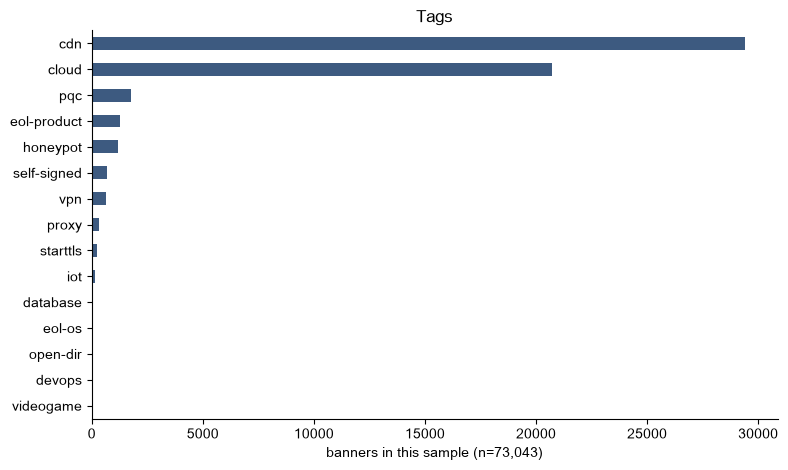

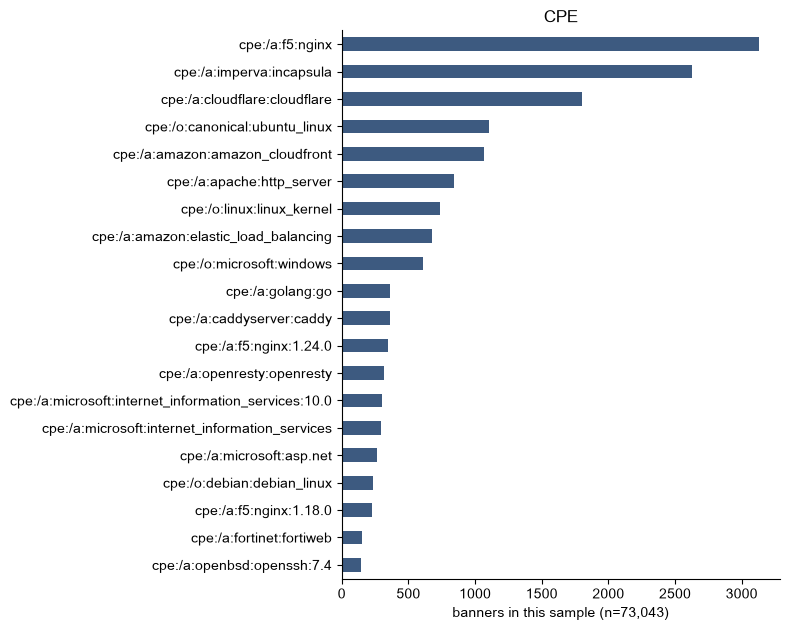

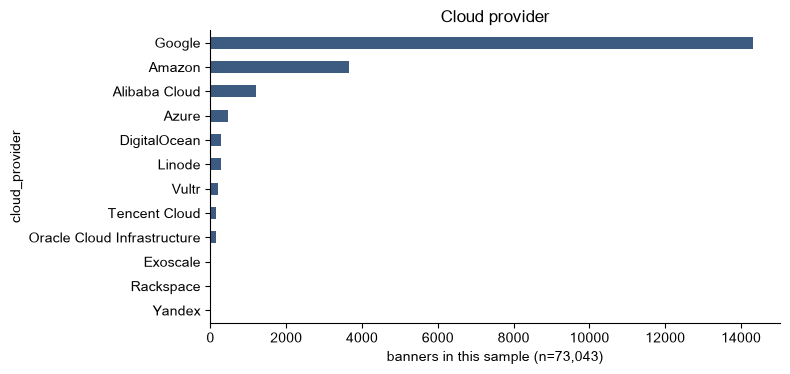

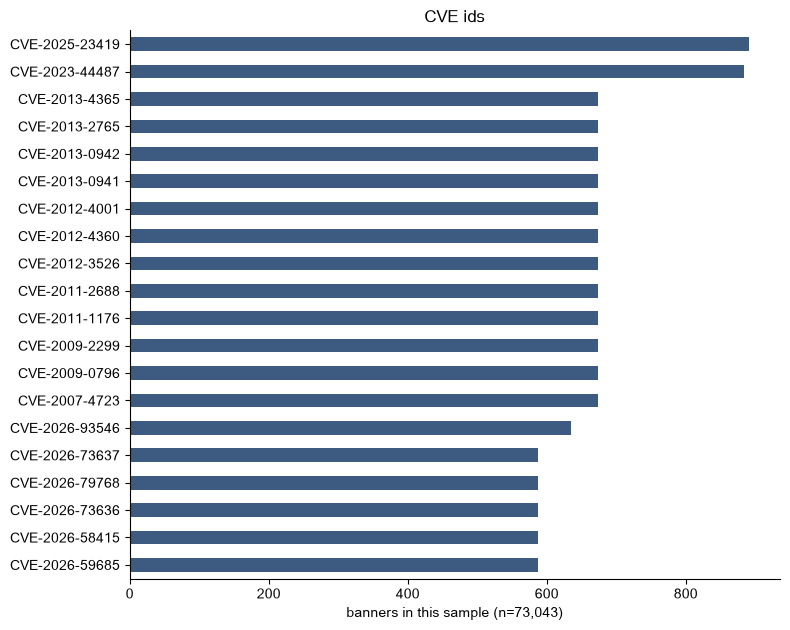

CVE-2025-23419    891
CVE-2023-44487    884
CVE-2013-4365     673
CVE-2013-2765     673
CVE-2013-0942     673
CVE-2013-0941     673
CVE-2012-4001     673
CVE-2012-4360     673
CVE-2012-3526     673
CVE-2011-2688     673
CVE-2011-1176     673
CVE-2009-2299     673
CVE-2009-0796     673
CVE-2007-4723     673
CVE-2026-93546    635
CVE-2026-73637    587
CVE-2026-79768    587
CVE-2026-73636    587
CVE-2026-58415    587
CVE-2026-59685    587
Name: count, dtype: int64

In [8]:
def explode_json_list(raw: pd.Series) -> pd.Series:
    values = []
    for item in raw.dropna():
        parsed = json.loads(item)
        if isinstance(parsed, list):
            values.extend(str(x) for x in parsed if x is not None)
    return pd.Series(values)


print("has_ssl", round(sample["has_ssl"].mean(), 3), "   has_vulns", round(sample["has_vulns"].mean(), 3))
print(sample.loc[sample["has_vulns"], "n_vulns"].describe())
top_counts(explode_json_list(sample["tags"]), title="Tags")
top_counts(explode_json_list(sample["cpes"]), n=20, title="CPE")
top_counts(sample["cloud_provider"], title="Cloud provider")
top_counts(explode_json_list(sample["vuln_ids"]), n=20, title="CVE ids")


In [9]:
cols = ["timestamp", "ip_str", "ipv6", "port", "org", "product", "module", "n_vulns", "vuln_ids"]
sample.loc[sample["has_vulns"], cols].head(20)


,timestamp,ip_str,ipv6,port,org,product,module,n_vulns,vuln_ids
38,2026-10-26 11:59:54.213076+00:00,84.234.97.80,NaN,80,TIPZOR MEDIA SRL,NaN,http,8,"[""CVE-2026-109618"",""CVE-2026-109619"",""CVE-2024-5458"",""CVE-2024-3566"",""CVE-2024-25117"",""CVE-2022-..."
242,2026-10-26 12:00:06.729652+00:00,152.232.214.180,NaN,8000,B2 Net Solutions Inc.,Squid http proxy,http-simple-new,61,"[""CVE-2026-47729"",""CVE-2026-50012"",""CVE-2026-33515"",""CVE-2026-33526"",""CVE-2026-32748"",""CVE-2025-..."
258,2026-10-26 12:00:05.331554+00:00,91.98.45.159,NaN,80,Hetzner Online GmbH,nginx,http,2,"[""CVE-2025-23419"",""CVE-2023-44487""]"
260,2026-10-26 11:52:56.703887+00:00,35.175.84.37,NaN,80,Amazon Technologies Inc.,nginx,http,12,"[""CVE-2023-44487"",""CVE-2021-3618"",""CVE-2017-20005"",""CVE-2021-23017"",""CVE-2019-20372"",""CVE-2019-9..."
288,2026-10-26 11:59:53.266433+00:00,8.139.211.56,NaN,2081,Aliyun Computing Co.LTD,OpenSSH,auto,38,"[""CVE-2026-106583"",""CVE-2026-106587"",""CVE-2026-106553"",""CVE-2026-106555"",""CVE-2026-106582"",""CVE-..."
289,2026-10-26 12:00:09.345485+00:00,176.104.58.198,NaN,8291,UnderNet LLC,MikroTik Winbox,mikrotik-routeros,4,"[""CVE-2022-45315"",""CVE-2022-45313"",""CVE-2021-3014"",""CVE-2018-5951""]"
349,2026-10-26 12:00:06.811708+00:00,94.57.254.195,NaN,80,EMIRATES TELECOMMUNICATIONS GROUP COMPANY (ETISALAT GROUP) PJSC,nginx,http,2,"[""CVE-2025-23419"",""CVE-2023-44487""]"
387,2026-10-26 12:00:13.433700+00:00,1.117.199.240,NaN,3306,"Tencent cloud computing (Beijing) Co., Ltd.",MySQL,mysql,35,"[""CVE-2023-22084"",""CVE-2023-22028"",""CVE-2023-22015"",""CVE-2023-22026"",""CVE-2023-22007"",""CVE-2023-..."
453,2026-10-26 12:00:13.612298+00:00,220.157.171.131,NaN,8085,Asahi Net,Apache httpd,https-simple-new,61,"[""CVE-2026-93546"",""CVE-2026-42535"",""CVE-2026-29170"",""CVE-2026-28780"",""CVE-2026-29169"",""CVE-2026-..."
528,2026-10-26 12:00:17.607372+00:00,43.210.37.86,NaN,6081,"Amazon.com, Inc.",NaN,auto,14,"[""CVE-2026-7210"",""CVE-2026-3087"",""CVE-2026-6019"",""CVE-2026-4519"",""CVE-2026-3644"",""CVE-2025-13462..."


## Keys the flat table does not show

Top-level keys depend on the probe. `ssh`, `mysql`, `hikvision`, and similar objects show up only on matching banners. This pass counts key names on the same sample. It does not keep the values.


In [10]:
def key_counts() -> pd.DataFrame:
    path = str(DATA).replace("'", "''")
    con = duckdb.connect()
    df = con.execute(f"""
        SELECT k AS key, count(*) AS banners
        FROM (
          SELECT unnest(json_keys(j)) AS k
          FROM (
            SELECT column0::JSON AS j
            FROM read_csv(
              '{path}',
              header = false,
              columns = {{'column0': 'VARCHAR'}},
              delim = '\x01',
              quote = '',
              escape = '',
              max_line_size = 50000000,
              strict_mode = false,
              ignore_errors = true
            )
          )
        )
        GROUP BY 1
        ORDER BY 2 DESC
    """).fetchdf()
    con.close()
    df["share"] = df["banners"] / max(len(sample), 1)
    return df


keys = key_counts()
keys.assign(share=lambda d: (d["share"] * 100).round(1).astype(str) + "%")


,key,banners,share
0,opts,73043,100.0%
1,os,73043,100.0%
2,hash,73043,100.0%
3,port,73043,100.0%
4,location,73043,100.0%
...,...,...,...
110,superset,1,0.0%
111,epmd,1,0.0%
112,hp_printer_embedded_web_server,1,0.0%
113,stun,1,0.0%


## Open one banner

`banner(i)` reads a single raw record from this same sample. Long strings are cut so an HTML body does not flood the cell. Pass a larger `max_chars` when you need the raw text.


In [11]:
def _shorten(value, limit: int):
    if isinstance(value, str) and len(value) > limit:
        return value[:limit] + f"… [{len(value):,} chars]"
    if isinstance(value, dict):
        return {k: _shorten(v, limit) for k, v in value.items()}
    if isinstance(value, list):
        head = [_shorten(v, limit) for v in value[:8]]
        if len(value) > 8:
            head.append(f"… {len(value) - 8} more")
        return head
    return value


def banner(index: int, max_chars: int = 400) -> dict:
    path = str(DATA).replace("'", "''")
    con = duckdb.connect()
    row = con.execute(f"""
        SELECT column0
        FROM read_csv(
          '{path}',
          header = false,
          columns = {{'column0': 'VARCHAR'}},
          delim = '\x01',
          quote = '',
          escape = '',
          max_line_size = 50000000,
          strict_mode = false,
          ignore_errors = true
        )
        LIMIT 1
        OFFSET {int(index)}
    """).fetchone()
    con.close()
    if row is None or row[0] is None:
        raise IndexError(index)
    return _shorten(json.loads(row[0]), max_chars)


banner(0)


{'data': 'HTTP/1.1 403 Forbidden\r\nDate: Mon, 26 Oct 2026 11:59:52 GMT\r\nContent-Type: text/html; charset=UTF-8\r\nContent-Length: 5630\r\nConnection: close\r\nAccept-Ch: Sec-CH-UA-Bitness, Sec-CH-UA-Arch, Sec-CH-UA-Full-Version, Sec-CH-UA-Mobile, Sec-CH-UA-Model, Sec-CH-UA-Platform-Version, Sec-CH-UA-Full-Version-List, Sec-CH-UA-Platform, Sec-CH-UA, UA-Bitness, UA-Arch, UA-Full-Version, UA-Mobile, UA-Model, UA-Pla… [2,202 chars]',
 'opts': {'vulns': [],
  'heartbleed': '2026/10/26 11:59:57 141.193.213.20:443 - SAFE\n'},
 'port': 443,
 'hostnames': ['jamasoftware.com'],
 'timestamp': '2026-10-26T11:59:52.579107',
 'domains': ['jamasoftware.com'],
 'location': {'area_code': None,
  'city': 'Austin',
  'country_code': 'US',
  'country_name': 'United States',
  'latitude': 30.2672,
  'longitude': -97.7431,
  'region_code': 'TX'},
 'org': 'WPEngine, Inc.',
 'isp': 'Cloudflare London, LLC',
 'os': None,
 'http': {'status': 403,
  'robots_hash': None,
  'redirects': [],
  'title_hash': -35

Change the index to any row in `sample`. This example opens the first banner in the sample that carries CVE ids, when there is one.


In [12]:
vuln_rows = sample.index[sample["has_vulns"]].tolist()
if not vuln_rows:
    print("No CVE map in this sample.")
else:
    i = vuln_rows[0]
    print("sample index", i)
    shown = banner(int(i))
    print("vulns:", json.dumps(shown.get("vulns"), indent=2)[:2000])
    print("keys:", sorted(shown))


sample index 38
vulns: {
  "CVE-2026-109618": {
    "cvss": 9.2,
    "cvss_version": 4.0,
    "cvss_v2": null,
    "references": [
      "https://github.com/php/php-src/security/advisories/GHSA-w8hw-w9fx-j79w",
      "http://www.openwall.com/lists/oss-security/2026/10/21/6",
      "http://www.openwall.com/lists/oss-security/2026/10/23/5",
      "https://cert-portal.siemens.com/productcert/html/ssa-566512.html",
      "https://www.wiz.io/blog/php2shell-php-rce"
    ],
    "summary": "PHP uses longjmp() for out-of-memory (OOM) errors to exit the current context and abort handling of the request. Some contexts may not properly account for this scenario and leave request memory in an uninitialized state before performing an allocation. The subsequent request cleanup procedure may read or branch on this memory. Multiple OOM strategies can consistently trigger this condition and le\u2026 [434 chars]",
    "verified": false,
    "epss": 0.11841,
    "ranking_epss": 0.96097
  },
  "CVE-2026-10

## Which rows name a real business

`attribute_business` reads the names on one banner: the name the scan requested, the website host, the hostnames, and the certificate name. It throws away names the host invented from the address, and names that sit in a host's or a site-builder's zone. The network owner is not consulted.

A row is kept when exactly one customer domain remains. A shared address that still shows several domains is left blank, because picking one would be a guess. A decoy is left blank too.

In [13]:
# A row is named only when one customer domain remains.
# The network owner (org, ASN, ISP) is the landlord, so it is never used as the business.
# subjectAltName is skipped: Shodan stores that extension as raw certificate bytes, and CN is the readable name.

import re

MULTI_PART_SUFFIXES = {
    "co.uk", "org.uk", "ac.uk", "gov.uk",
    "com.au", "net.au", "org.au",
    "co.jp", "ne.jp", "or.jp", "ac.jp", "go.jp", "ed.jp", "gr.jp",
    "com.br", "com.mx", "com.tr", "com.sg", "com.cn", "com.tw", "com.hk",
    "co.nz", "co.in", "co.za", "co.kr", "co.th", "co.id", "co.il",
    "com.ar", "com.co", "com.vn", "com.my",
    "go.th", "ac.th", "or.th", "in.th", "net.th",
}

# A name under one of these zones was issued by the host or a site builder.
# The label on the left is a server id or a page slug, not the tenant's own domain.
PLATFORM_ZONES = {
    "incapdns.net", "impervadns.net", "imperva.com",
    "googleusercontent.com", "1e100.net",
    "amazonaws.com", "cloudfront.net", "awsglobalaccelerator.com", "amazonlightsail.com",
    "akamaitechnologies.com", "akamai.net", "akamaiedge.net", "akamaized.net",
    "edgesuite.net", "edgekey.net",
    "cloudflare.net", "cloudflaressl.com",
    "azurewebsites.net", "wpengine.com", "wpenginepowered.com",
    "bluehost.com", "unifiedlayer.com", "secureserver.net",
    "your-server.de", "contaboserver.net", "hosteurope.de", "kasserver.com",
    "inmotionhosting.com", "goodsrv.de", "siteserverconfig.com",
    "flyio.net", "hwclouds-dns.com", "scw.cloud",
    "vultrusercontent.com", "linodeusercontent.com", "ondigitalocean.com",
    "ovh.net", "ovh.us",
    "mystrikingly.com", "bizmw.com", "p-kit.com", "my-free.website", "bandzoogle.com",
    "herokuapp.com", "github.io", "netlify.app", "vercel.app", "myshopify.com",
    "cloudapp.net", "aliyuncs.com", "myqcloud.com", "windows.net", "ctcdn.cn",
    "notexist.com", "in-addr.arpa", "ip6.arpa",
}

# Longer than two letters and not in this set: fail closed. Two-letter country suffixes are accepted.
KNOWN_LONG_SUFFIXES = {
    "com", "net", "org", "edu", "gov", "mil", "info", "biz", "app", "dev", "cloud",
    "online", "site", "shop", "store", "tech", "xyz", "name", "mobi", "pro", "asia",
    "blog", "digital", "agency", "studio", "group", "world", "live", "today", "link",
    "support", "network", "systems", "software", "solutions", "services", "media",
    "ninja", "website", "space", "email", "company",
}

PLACEHOLDER_NAMES = {
    "localhost", "server", "plesk", "kube-apiserver", "router.asus.com",
    "invalid2.invalid", "invalid.incapsula.com", "notexist.com", "www.notexist.com",
}

ADDRESS_LABELS = {
    "static", "dynamic", "dynamicip", "dyn", "dsl", "adsl", "pool", "ftth",
    "pppoe", "ptr", "rev", "dialup", "broadband", "abo", "unused", "webpack",
}


def registrable_domain(name: str) -> str | None:
    """Registered domain of a hostname, or None when the name cannot be one."""
    if not isinstance(name, str):
        return None
    host = name.strip().lower().rstrip(".")
    if host.startswith("*."):
        host = host[2:]
    host = host.split("/")[0].split(" ")[0]
    if host.count(":") == 1 and host.rsplit(":", 1)[-1].isdigit():
        host = host.rsplit(":", 1)[0]
    elif ":" in host:
        return None
    labels = [part for part in host.split(".") if part]
    if len(labels) < 2 or any(len(part) > 63 for part in labels):
        return None
    if not all(re.fullmatch(r"[a-z0-9-]+", part) for part in labels):
        return None
    suffix = labels[-1]
    if not suffix.isalpha() or (len(suffix) != 2 and suffix not in KNOWN_LONG_SUFFIXES):
        return None
    last_two = ".".join(labels[-2:])
    if last_two in MULTI_PART_SUFFIXES:
        if len(labels) < 3:
            return None
        domain = ".".join(labels[-3:])
    else:
        domain = last_two
    if domain in MULTI_PART_SUFFIXES or domain in PLATFORM_ZONES:
        return None
    return domain


def _ip_forms(ip: str) -> list[str]:
    if not isinstance(ip, str) or ip.count(".") != 3:
        return []
    parts = ip.split(".")
    if not all(part.isdigit() for part in parts):
        return []
    forms = []
    for sequence in (parts, list(reversed(parts))):
        forms.extend([
            ".".join(sequence),
            "-".join(sequence),
            "-".join(part.zfill(3) for part in sequence),
            "".join(sequence),
            "".join(part.zfill(3) for part in sequence),
        ])
    return forms


def _address_shaped(hostname: str, ip: str) -> bool:
    """True when the hostname was generated from the machine's address.

    Carriers and hosts do this (dashed octets, `static.`, `dip0`, a long hex label).
    A name a company chose does not look like that, so those names are eligible.
    """
    host = hostname.lower()
    if any(form and form in host for form in _ip_forms(ip)):
        return True
    if re.search(r"\d{1,3}x\d{1,3}x\d{1,3}x\d{1,3}", host):
        return True
    for label in host.split("."):
        if label in ADDRESS_LABELS or label.startswith("dip"):
            return True
        if re.fullmatch(r"ip-?\d.*", label) or re.fullmatch(r"host\d+", label):
            return True
        if re.fullmatch(r"[a-z]{0,3}\d{5,}", label) or re.fullmatch(r"[a-f0-9]{8,}", label):
            return True
        if len(re.findall(r"\d{1,3}", label)) >= 3 and "-" in label:
            return True
        digits = sum(character.isdigit() for character in label)
        letters = sum(character.isalpha() for character in label)
        if len(label) >= 6 and digits >= 3 and digits >= letters:
            return True
    return False


def _names_on_banner(banner: dict) -> list[str]:
    names = []
    requested = ((banner.get("_shodan") or {}).get("options") or {}).get("hostname")
    if isinstance(requested, str):
        names.append(requested)
    http_host = (banner.get("http") or {}).get("host")
    if isinstance(http_host, str):
        names.append(http_host)
    names.extend(name for name in (banner.get("hostnames") or []) if isinstance(name, str))
    subject = ((banner.get("ssl") or {}).get("cert") or {}).get("subject") or {}
    if isinstance(subject, dict) and isinstance(subject.get("CN"), str):
        names.append(subject["CN"])
    return names


def attribute_business(banner: dict) -> dict:
    """Return the one customer domain this banner supports, or no name.

    Host-made names and platform zones are removed first. Zero domains left means
    this row cannot be tied to a customer. More than one domain means several
    tenants share the address, and choosing among them would be a guess.
    Decoys (tag `honeypot`) are never named: the name is bait.
    """
    if "honeypot" in (banner.get("tags") or []):
        return {"business": None, "outcome": "decoy"}
    ip = banner.get("ip_str") or ""
    domains = set()
    for name in _names_on_banner(banner):
        if name.strip().lower().rstrip(".") in PLACEHOLDER_NAMES:
            continue
        if _address_shaped(name, ip):
            continue
        domain = registrable_domain(name)
        if domain:
            domains.add(domain)
    if not domains:
        return {"business": None, "outcome": "no customer domain"}
    if len(domains) > 1:
        return {"business": None, "outcome": "several businesses"}
    return {"business": next(iter(domains)), "outcome": "attributed"}


5,282 of 73,043 rows named a single business (7.2%)
3,769 distinct businesses

outcome
no customer domain    65839
attributed             5282
decoy                  1189
several businesses      733


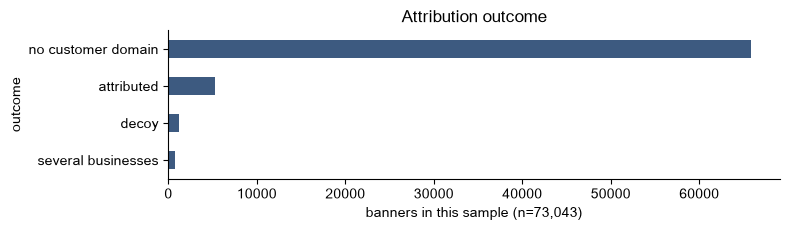

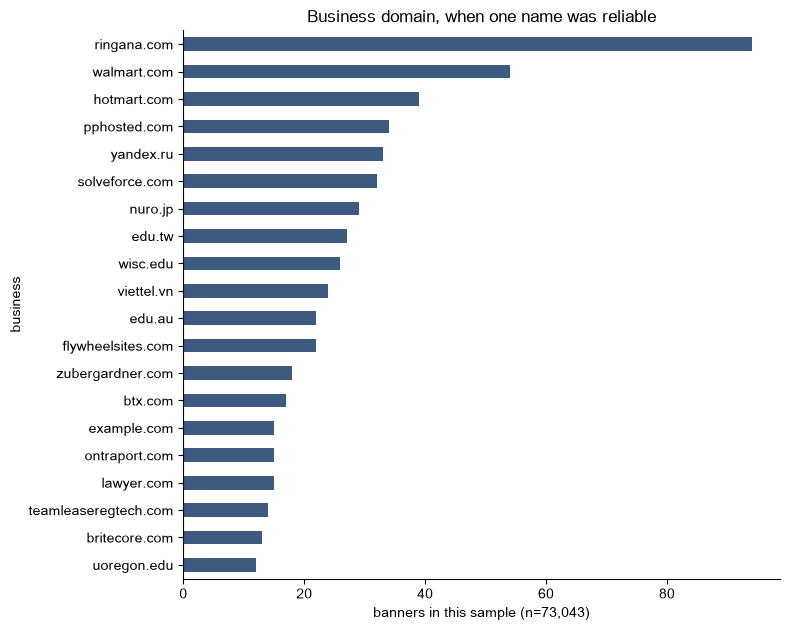

,business
0,jamasoftware.com
3,oyatsu-town.com
37,commonlit.org
43,campoutinc.com
55,sme.sk
62,azure.com
94,aws.dev
122,firstbanknigeria.com
135,edu.au
150,motherjones.com


In [14]:
def load_banners() -> list[dict]:
    path = str(DATA).replace("'", "''")
    con = duckdb.connect()
    rows = con.execute(f"""
        SELECT column0
        FROM read_csv(
          '{path}',
          header = false,
          columns = {{'column0': 'VARCHAR'}},
          delim = '\x01',
          quote = '',
          escape = '',
          max_line_size = 50000000,
          strict_mode = false,
          ignore_errors = true
        )
    """).fetchall()
    con.close()
    return [json.loads(line) for (line,) in rows if line]


banners = load_banners()
attributed = pd.DataFrame(attribute_business(banner) for banner in banners)
if len(attributed) == len(sample):
    sample = sample.copy()
    sample["business"] = attributed["business"].to_numpy()

named = int(attributed["business"].notna().sum())
print(f"{named:,} of {len(attributed):,} rows named a single business ({named / len(attributed):.1%})")
print(f"{attributed['business'].nunique():,} distinct businesses")
print()
print(attributed["outcome"].value_counts().to_string())
top_counts(attributed["outcome"], title="Attribution outcome")
top_counts(attributed["business"], n=20, title="Business domain, when one name was reliable")
attributed.loc[attributed["outcome"].eq("attributed"), ["business"]].head(15)
